In [44]:
from pathlib import Path
from itertools import combinations
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import seaborn as sns
import numpy as np
from scipy.interpolate import griddata
from matplotlib.patches import Patch



MODEL = "Scalar"
INPUT_PICKLE = Path('../Recast/Scalar/Scalar_smodels.pcl')


# Mass columns are the ones used in the uploaded SModelS notebooks.
MASS_COL = "mass.5000002"
DM_MASS_COL = "mass.5000012"
K_FACTOR = 1.0
R_CUT = 1.0 / K_FACTOR

SHOW_TOTAL_EXCLUSION = True
FILL_EXCLUDED_REGIONS = True
FILL_LEFT_MASS = 200.0     # Exactly as in plotExclusion-DirectSearches
FILL_ALPHA = 0.18          # Exactly as in plotExclusion-DirectSearches
BENCHMARK = (1500.0, 100.0)
SHOW_BENCHMARK = True
X_LIM = (300.0, 1750.0)
Y_LIM = (40.0, 500.0)
LEGEND_FONTSIZE = 15
INTERPOLATION_RESOLUTION = 200  # auxPlots original grid used to FIND the r=1 contours

# The PCHIP smoothing you used for Zprime, adapted to M_limit(deltaM).
SMOOTH_SIGMA = 1.2          # Gaussian width IN OUTPUT GRID POINTS; 0 disables smoothing
PCHIP_KNOT_SPACING = 2.0    # GeV in deltaM, knot spacing before dense PCHIP reconstruction
BOUNDARY_NPTS = 650         # dense common deltaM grid, including both Y_LIM endpoints
FILL_GAP_TOLERANCE_Y = 3.0   # GeV; only tiny gaps between supported contours
FILL_GAP_TOLERANCE_X = 20.0  # GeV; require neighboring masses to be close
# 'individual': transparent fills for each analysis, 'total': one neutral combined fill, 'none': no fill.
FILL_STYLE = 'individual'  # Colored analysis fills; 'total' for neutral, 'none' for contours only
# Optional targeted repair of *short internal* gaps only, based on the two contour
# endpoints. This does NOT extrapolate above or below the analysis contour's support.
# Set to {} to retain all raw discontinuities. Repairs are visualization-only.
ANALYSIS_GAP_REPAIR = {
    'CMS-SUS-19-010': {'max_delta_y': 32.0, 'max_delta_m': 85.0}
}
SHOW_REPAIR_DIAGNOSTICS = True
# Raw combined-all contour is saved but NOT used for the black line (it is interpolated independently).

# Distinct lines with matching translucent colors.
PALETTE = [
    "#0072B2",  # Blue
    "#E41A1C",  # Red
    "#009E73",  # Green
    "#984EA3",  # Purple
    "#F781BF",  # Pink
    "#00A6A6",  # Teal
    "#4D4D4D",  # Dark gray
]

pd.option_context('display.max_columns', -1)

pd.options.mode.chained_assignment = None #Disable copy warnings
# plt.style.use('fivethirtyeight') #Set style
# mpl.rcParams.update({'figure.figsize' : (15,10)})  #Set general plotting options
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.8)




## Load Results

In [45]:
if not INPUT_PICKLE.exists():
    raise FileNotFoundError(f"Run ../Recast/getSModelSData.ipynb first to generate {INPUT_PICKLE}.")
dataDF = pd.read_pickle(INPUT_PICKLE).reset_index(drop=True).copy()
for col in (MASS_COL, DM_MASS_COL):
    if col not in dataDF:
        raise KeyError(f"Mass column {col} not found. Available: {[c for c in dataDF if c.startswith('mass.')]}")
dataDF['deltaM'] = pd.to_numeric(dataDF[MASS_COL]) - pd.to_numeric(dataDF[DM_MASS_COL])

# Select only points with deltaM > 50 GeV and M > 500 GeV
dataDF = dataDF[(dataDF['deltaM'] > Y_LIM[0]) & (dataDF[MASS_COL] > X_LIM[0])].copy()



### Get list of excluded points and relevant analyses

In [46]:
excludedDF = dataDF[dataDF['ExptRes.result0.r'] > 1.0].copy()
print(f"Found {len(excludedDF)} excluded points (r>1) out of {len(dataDF)} total points.")

## Get minimal set of analyses excluding all excluded points.
excluded_analysis_ids = {}
for index, row in excludedDF.iterrows():
    for col in dataDF.columns:
        if col.startswith('ExptRes.result') and col.endswith('.r'):
            if row[col] > 1.0:
                anaID = row[col[:-2]+'.AnalysisID']
                excluded_analysis_ids.setdefault(anaID, [])
                excluded_analysis_ids[anaID].append(index)

excluded_analysis_ids_sorted = {anaID : excluded_analysis_ids[anaID] for anaID in sorted(excluded_analysis_ids.keys(), key=lambda x: len(excluded_analysis_ids[x]), reverse=True)}
excluded_analysis_ids = excluded_analysis_ids_sorted
print(f"{len(excluded_analysis_ids)} excluding analysis IDs")
for anaID,indices in sorted(excluded_analysis_ids.items(), key=lambda x: len(x), reverse=True):
    print(f"  {anaID}: {len(indices)} excluded points")

Found 297 excluded points (r>1) out of 729 total points.
23 excluding analysis IDs
  CMS-SUS-20-002: 215 excluded points
  CMS-SUS-19-006-agg: 206 excluded points
  CMS-SUS-19-010: 194 excluded points
  ATLAS-SUSY-2018-08: 186 excluded points
  CMS-SUS-19-006: 150 excluded points
  ATLAS-SUSY-2018-12: 144 excluded points
  CMS-SUS-19-009: 140 excluded points
  CMS-SUS-16-033: 135 excluded points
  CMS-SUS-16-036: 57 excluded points
  ATLAS-SUSY-2016-15: 44 excluded points
  CMS-SUS-16-051: 43 excluded points
  ATLAS-SUSY-2016-16: 35 excluded points
  CMS-SUS-19-011: 26 excluded points
  CMS-SUS-17-010: 24 excluded points
  CMS-SUS-18-004: 24 excluded points
  CMS-SUS-16-050-agg: 19 excluded points
  CMS-SUS-16-050: 18 excluded points
  CMS-PAS-SUS-16-052: 12 excluded points
  CMS-SUS-17-005: 11 excluded points
  CMS-PAS-SUS-16-052-agg: 11 excluded points
  CMS-SUS-16-009: 8 excluded points
  ATLAS-SUSY-2016-17: 8 excluded points
  ATLAS-SUSY-2015-02: 1 excluded points


## Get minimal set of analyses

In [47]:
minimal_sets = []
all_excluded_indices = set(excludedDF.index)
for size in range(len(excluded_analysis_ids) + 1):
    minimal_sets = []
    for analyses_set in combinations(excluded_analysis_ids.keys(), size):
        excluded_indices_by_set = set([])
        for anaID in analyses_set:
            excluded_indices_by_set.update(excluded_analysis_ids[anaID])
        if len(all_excluded_indices) != len(excluded_indices_by_set):
            continue
        if all_excluded_indices.issubset(excluded_indices_by_set):
            minimal_sets.append(analyses_set)
    if minimal_sets:
        break
if not minimal_sets:
    minimal_sets = [list(excluded_analysis_ids.keys())]
    
# Sort sets by total excluded points covered, descending.
minimal_sets = sorted(minimal_sets, key=lambda x: sum(len(excluded_analysis_ids[anaID]) for anaID in x), reverse=True)

for i,m_set in enumerate(minimal_sets):
    excluded_indices_by_set = set([])
    for anaID in m_set:
        excluded_indices_by_set.update(excluded_analysis_ids[anaID])
    print(f"\nMinimal set {i+1}:")
    print(f"  Excluded points: {len(excluded_indices_by_set)}")
    for anaID in m_set:
        print("  ", anaID, len(excluded_analysis_ids[anaID]), "excluded points")

# Use the first minimal set for plotting.
minimal_analyses = {anaID: excluded_analysis_ids[anaID] for anaID in minimal_sets[0]}


Minimal set 1:
  Excluded points: 297
   CMS-SUS-20-002 215 excluded points
   CMS-SUS-19-006-agg 206 excluded points
   CMS-SUS-19-010 194 excluded points


## Get dataframe for each analysis

In [48]:
anaDFDict = {}
anaColumns = np.array([col for col in dataDF.columns if col.startswith('ExptRes.result') and col.endswith('.AnalysisID')])
rColumns = np.array([col for col in dataDF.columns if col.startswith('ExptRes.result') and col.endswith('.r')])
for anaID in minimal_analyses:
    anaDFDict[anaID] = dataDF.drop(columns=np.concatenate((anaColumns, rColumns))).copy()
    anaDFDict[anaID]['r'] = 0.0
    for irow,row in dataDF.iterrows():
        if not anaID in row[anaColumns].values:
            continue
        r_values = row[rColumns[np.where(row[anaColumns].values == anaID)]].values
        r = max(r_values)
        anaDFDict[anaID].loc[irow,'r'] = r



## Excluded scan points by analysis

In [49]:
# Fixed colors for each CMS analysis
FIXED_COLORS = {
    'CMS-SUS-20-002': '#0072B2',  # Blue
    'CMS-SUS-19-006': '#E41A1C',  # Red
    'CMS-SUS-19-010': '#009E73',  # Green
}

color_by_analysis = {
    a: FIXED_COLORS.get(a.removesuffix('-agg'), '#333333')
    for a in minimal_analyses
}

In [50]:
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import PchipInterpolator

def smooth(x,y,sigma=1.0,npts=100):
    # Smooth in log-space on a uniform mass grid
    xg = np.linspace(x.min(), x.max(), npts)
    yg = PchipInterpolator(x, y)(xg)
    yg = gaussian_filter1d(yg, sigma=sigma, 
                           mode='nearest')
    return xg,yg

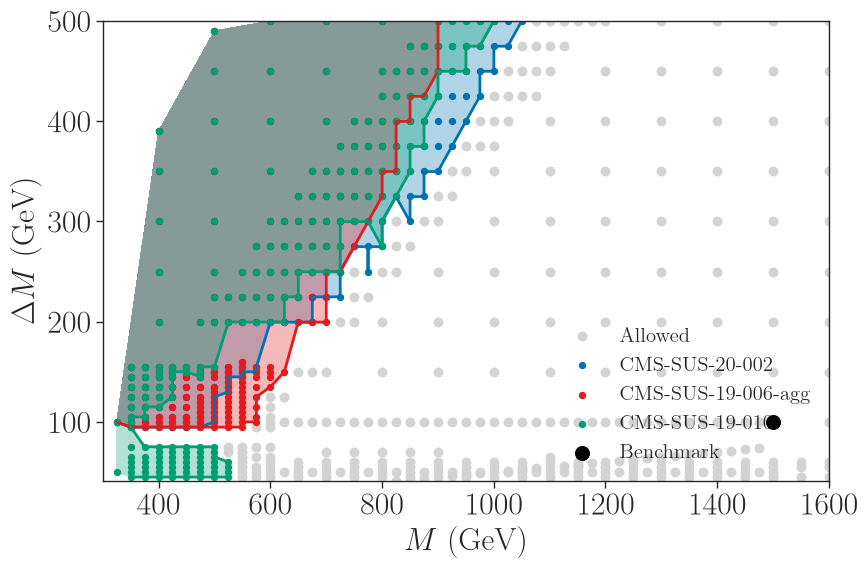

In [51]:
fig = plt.figure(figsize=(9, 6))
allowed = dataDF[~dataDF.index.isin(excludedDF.index)]
plt.scatter(allowed[MASS_COL], allowed.deltaM, s=40, c='lightgray', label='Allowed')

x = dataDF[MASS_COL].values
y = dataDF.deltaM.values
for ana,indices_excluded in minimal_analyses.items():
    anaDF = dataDF.loc[indices_excluded]
    plt.scatter(anaDF[MASS_COL], anaDF.deltaM, s=20, color=color_by_analysis[ana], label=ana)

    # z = 1 if the grid point is in the subset, 0 otherwise.
    z = np.array([1.0 if index in indices_excluded else 0.0 for index in dataDF.index])
    # Triangulate the irregular grid and draw the 0.5 boundary
    triang = tri.Triangulation(x, y)
    plt.tricontourf(triang, z, levels=[0.99, 10.1], colors=[color_by_analysis[ana]], alpha=0.3)  # filled region
    plt.tricontour(triang, z, levels=[0.99], colors=color_by_analysis[ana], linewidths=2)  


if SHOW_BENCHMARK:
    plt.scatter(*BENCHMARK, c='black', edgecolors='black', s=100, label='Benchmark', zorder=7)
plt.xlabel(r'$M$ (GeV)', fontsize=23)
plt.ylabel(r'$\Delta M$ (GeV)', fontsize=23)
plt.xlim(300, 1600)
plt.tick_params(axis='both', labelsize=23)
plt.legend(loc='lower right', fontsize=LEGEND_FONTSIZE, framealpha=0)
fig.tight_layout()
plt.show()

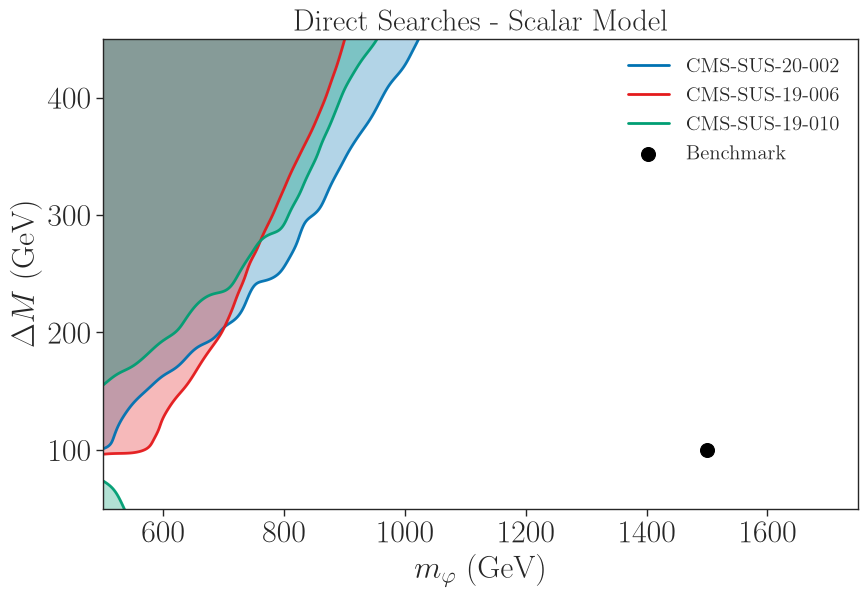

In [52]:
from scipy.ndimage import gaussian_filter
fig = plt.figure(figsize=(9, 6))
allowed = dataDF[~dataDF.index.isin(excludedDF.index)]
# plt.scatter(allowed[MASS_COL], allowed.deltaM, s=40, c='lightgray', label='Allowed')
for ana,anaDF_all in anaDFDict.items():
    label = ana.replace('-agg','')
    x = anaDF_all[MASS_COL].values.astype(float)
    y = anaDF_all.deltaM.values.astype(float)
    logr = np.log10(np.clip(anaDF_all.r.values.astype(float), 1e-3, None))
    xi = np.linspace(X_LIM[0], X_LIM[1], 1000)
    yi = np.linspace(Y_LIM[0], Y_LIM[1], 1000)
    X, Y = np.meshgrid(xi, yi)
    Z = griddata((x, y), logr, (X, Y), method='linear', 
                 fill_value=0.0)
    Z_smooth = gaussian_filter(Z, sigma=(10.0,10.0), mode='nearest')
    # z = 1 if the grid point is in the subset, 0 otherwise.                                                                                                
    plt.contourf(X, Y, Z_smooth, levels=[0.0,10.0], 
                 colors=[color_by_analysis[ana]], alpha=0.3)
    contours = plt.contour(X, Y, Z_smooth, levels=[0.0], alpha=0.95,
                           colors=[color_by_analysis[ana]], linewidths=2.0, linestyles='solid')
    # Plot non-smoothed curves as a cross check:
    # plt.contour(X, Y, Z, levels=[0.0], alpha=0.5,
                            #    colors=[color_by_analysis[ana]], linewidths=2.0, linestyles='dashed')
    plt.plot([], [], color=color_by_analysis[ana], lw=2.0, label=label)   # legend proxy


if SHOW_BENCHMARK:
    plt.scatter(*BENCHMARK, c='black', edgecolors='black', s=100, label='Benchmark', zorder=7)
plt.xlabel(r'$m_{\varphi}$ (GeV)', fontsize=23)
plt.ylabel(r'$\Delta M$ (GeV)', fontsize=23)
plt.xlim(500.0, X_LIM[1])
plt.ylim(50.,450.)
plt.tick_params(axis='both', labelsize=23)
plt.legend(loc='upper right', fontsize=LEGEND_FONTSIZE, framealpha=0)
fig.tight_layout()
plt.title('Direct Searches - Scalar Model',fontsize=22)
plt.savefig('../paper_plots/directSearches_Scalar.png',dpi=300, bbox_inches='tight')
plt.show()
